# Network Analysis Project: e-mail networks (email-Eu-core)
## Notebook 2: RQ2 - central actors and bridges (Section 5.2) + dataset table (Section 3)

**RQ2: Who are the central actors, and who bridges departments?**

**What this notebook does, in short**
1. Downloads the data and writes the group's shared loader (same as Notebooks 1 and 3).
2. Builds the **dataset table** for Section 3 (nodes, edges, isolates of the 5 networks) and checks our department-14 network against the SNAP temporal file `Dept3`.
3. Computes six centrality measures + the k-core on the **whole network**.
4. Finds the **top-10 members** per measure, the **Spearman correlations** between measures, and how concentrated centrality is.
5. Finds the **bridges** (high betweenness + many contacts in other departments) and tests the link with a permutation test.
6. Checks how much contact between departments **depends** on these bridges (removal experiment).
7. Saves tables (CSV + LaTeX), two figures, a Gephi file (`.gexf`) and `rq2_summary.json` into `results/`.

Each measure follows the report rule **A → B → C**: phenomenon → measure → what it means for e-mail here.

| Measure (B) | NetworkX | A: phenomenon / C: meaning for e-mail |
|---|---|---|
| **In-degree** | `G.in_degree()` | from how many colleagues a member receives e-mail → *popular recipient* |
| **Out-degree** | `G.out_degree()` | to how many colleagues a member writes → *broadcaster* |
| **PageRank** | `nx.pagerank(G, alpha=0.85)` | receives e-mail from members who themselves receive a lot → *prestige* |
| **HITS hubs / authorities** | `nx.hits(G)` | hub = writes to many good authorities; authority = written to by many good hubs → *many people write to them* |
| **Betweenness** | `nx.betweenness_centrality(G)` | lies on many shortest e-mail paths → *broker between groups* |
| **Core number (k-core)** | `nx.core_number(G.to_undirected())` | belongs to a densely connected centre → *in the institution's core* |
| **External share** | own code | share of a member's contacts in **other** departments → *works across the department boundary* |

**How to use it (Google Colab or Jupyter):** run the cells from top to bottom. The whole notebook takes about 2-3 minutes.

## Step 1: Data and the shared loader

- Downloads the two SNAP files into `data/` **only if they are not already there**.
- The second cell writes `load_networks.py`, the group's **shared loader**. It is an **exact copy** of Notebooks 1 and 3, so running it never changes anything.

In [1]:
import urllib.request
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)

FILES = {
    "email-Eu-core.txt.gz": "https://snap.stanford.edu/data/email-Eu-core.txt.gz",
    "email-Eu-core-department-labels.txt.gz": "https://snap.stanford.edu/data/email-Eu-core-department-labels.txt.gz",
}
for name, url in FILES.items():
    target = DATA / name
    if target.exists():
        print(f"already there: {target}")
    else:
        print(f"downloading {name} ...")
        urllib.request.urlretrieve(url, target)

already there: data/email-Eu-core.txt.gz
already there: data/email-Eu-core-department-labels.txt.gz


In [2]:
%%writefile load_networks.py
"""Shared loader for the email-Eu-core networks (used by every group member)."""
import gzip                       # to read the compressed .gz files directly
from collections import Counter   # to count how many people are in each department
from pathlib import Path          # to build file paths that work on every computer

import networkx as nx

DATA = Path(__file__).parent / "data"  # the data folder next to this file
SEED = 42      # fixed random seed: everyone gets the same "random" results
N_DEPTS = 4    # number of largest departments analysed as separate networks


def _open(path):
    """Open a file as text, whether it is compressed (.gz) or not."""
    path = Path(path)
    return gzip.open(path, "rt") if path.suffix == ".gz" else open(path)


def load_whole():
    """Build the whole institution network as a directed graph with department labels."""
    G = nx.DiGraph()  # DiGraph = directed graph (edges have a direction)

    # 1) Add every person as a node, with their department stored as attribute "dept".
    #    Doing this first also keeps people who never sent/received an e-mail (isolates).
    with _open(DATA / "email-Eu-core-department-labels.txt.gz") as f:
        for line in f:
            if line.strip():                       # skip empty lines
                node, dept = map(int, line.split())
                G.add_node(node, dept=dept)

    # 2) Add one directed edge u -> v for every line "u v" (u sent at least one e-mail to v).
    #    A DiGraph keeps at most one edge per ordered pair, so the network is unweighted.
    with _open(DATA / "email-Eu-core.txt.gz") as f:
        for line in f:
            if line.strip():
                u, v = map(int, line.split()[:2])
                G.add_edge(u, v)

    # 3) Remove self-loops (e-mails a person sent to themselves).
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    return G


def largest_departments(G, k=N_DEPTS):
    """Return the IDs of the k largest departments (ties broken by the smaller department ID)."""
    sizes = Counter(d for _, d in G.nodes(data="dept"))  # {department: number of members}
    ranked = sorted(sizes.items(), key=lambda x: (-x[1], x[0]))  # biggest first
    return [d for d, _ in ranked[:k]]


def dept_network(G, dept):
    """Network of one department: its members + only the e-mails among them (induced subgraph)."""
    members = [n for n, d in G.nodes(data="dept") if d == dept]
    return G.subgraph(members).copy()  # .copy() makes it an independent graph


def load_all():
    """Return a dictionary with the whole network and the N_DEPTS largest department networks."""
    G = load_whole()
    nets = {"whole": G}
    for dept in largest_departments(G):
        nets[f"dept{dept}"] = dept_network(G, dept)  # e.g. "dept4" = department with ID 4
    return nets


if __name__ == "__main__":
    # Quick check when the file is run directly: print the size of every network.
    for name, H in load_all().items():
        print(f"{name:7s}  nodes={H.number_of_nodes():5d}  edges={H.number_of_edges():6d}")

Overwriting load_networks.py


## Step 2: Settings

All parameters in one place. **Do not change `SEED`** (group rule). Same figure style as Notebook 3, so all figures in the report look alike.

In [3]:
import importlib
import json
import gzip
import urllib.request

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import pandas as pd
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr

import load_networks
importlib.reload(load_networks)
from load_networks import SEED, dept_network, largest_departments, load_all

N_PERM = 5000          # permutations for the bridge test (Step 8)
N_RANDOM_REMOVAL = 100 # random sets of members removed as a baseline (Step 9)
TOP_K = 10             # top-k members per measure
TOP_BETWEENNESS = 0.90 # "high betweenness" = top 10% of members
TOP_EXTERNAL = 0.75    # "high external share" = top 25% of members

OUT = Path("results")
OUT.mkdir(exist_ok=True)

plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#8a8985",
                     "axes.labelcolor": "#2b2b29", "xtick.color": "#52514e", "ytick.color": "#52514e"})
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#8a8985", "#1f9e6e"

summary = {"seed": SEED, "n_perm": N_PERM, "n_random_removal": N_RANDOM_REMOVAL}


def save_table(df, name, float_format="%.3f", index=True):
    """Save a table as CSV (Excel) and LaTeX (report)."""
    df.to_csv(OUT / f"{name}.csv", index=index)
    df.to_latex(OUT / f"{name}.tex", float_format=float_format, index=index, na_rep="--")
    print(f"saved results/{name}.csv and .tex")


def p_upper(null, observed):
    """One-sided permutation p-value: share of null values >= observed (with +1 correction)."""
    null = np.asarray(null)
    return (np.sum(null >= observed) + 1) / (len(null) + 1)

## Step 3: The five networks (Section 3, dataset table)

**Expected (Notebook 1, Table 1):** whole network 1,005 nodes and 24,929 directed edges; departments 4, 14, 1, 21 with 109, 92, 65, 61 nodes.

For Section 3 we also report the undirected (OR rule) edges and the isolated nodes of each network. In a department network a member is *isolated* when they send no e-mail to, and receive none from, their own department (they may still e-mail other departments).

In [4]:
nets = load_all()
G = nets["whole"]
U = G.to_undirected()                     # OR rule
n = G.number_of_nodes()

rows = {}
for name, H in nets.items():
    rows["Whole" if name == "whole" else f"Dept {name[4:]}"] = {
        "nodes": H.number_of_nodes(),
        "share of members": H.number_of_nodes() / n,
        "edges (directed)": H.number_of_edges(),
        "edges (undirected, OR)": H.to_undirected().number_of_edges(),
        "isolated nodes": nx.number_of_isolates(H),
    }
table_networks = pd.DataFrame(rows)
display(table_networks)
save_table(table_networks, "table_3_networks", float_format="%.3f")

assert (n, G.number_of_edges()) == (1005, 24929)
self_loops_removed = 25571 - G.number_of_edges()    # 25,571 lines in the SNAP file
print("self-loops removed:", self_loops_removed)
summary["networks"] = table_networks.T.to_dict()
summary["self_loops_removed"] = self_loops_removed

,Whole,Dept 4,Dept 14,Dept 1,Dept 21
nodes,1005.0,109.000000,92.000000,65.000000,61.000000
share of members,1.0,0.108458,0.091542,0.064677,0.060697
edges (directed),24929.0,1167.000000,1506.000000,502.000000,601.000000
"edges (undirected, OR)",16064.0,745.000000,973.000000,331.000000,355.000000
isolated nodes,19.0,8.000000,3.000000,6.000000,15.000000


saved results/table_3_networks.csv and .tex
self-loops removed: 642


### Cross-check with the SNAP temporal files

SNAP also publishes four *temporal* department networks (`Dept1`-`Dept4`), but their node IDs do **not** match the whole network and they have no department label, so we could not link them to the 42 departments. This is why the group uses **induced subgraphs** of the 4 largest labelled departments instead.

One check is still possible: SNAP's `Dept3` has 89 nodes and 1,506 static edges, the same number of edges as our department 14. If, after removing self-loops, it has the same degree sequence and reciprocity as our department 14 (without its isolated members), the two are very likely the same department, which supports our construction.

In [5]:
url = "https://snap.stanford.edu/data/email-Eu-core-temporal-Dept3.txt.gz"
target = DATA / "email-Eu-core-temporal-Dept3.txt.gz"
if not target.exists():
    urllib.request.urlretrieve(url, target)

D3 = nx.DiGraph()
with gzip.open(target, "rt") as f:
    for line in f:
        if line.strip():
            u, v, _ts = map(int, line.split())   # timestamp ignored (static network)
            if u != v:
                D3.add_edge(u, v)

d14 = dept_network(G, 14)
d14_active = d14.subgraph([v for v in d14 if d14.degree(v) > 0])
same = (sorted(d for _, d in D3.in_degree()) == sorted(d for _, d in d14_active.in_degree())
        and sorted(d for _, d in D3.out_degree()) == sorted(d for _, d in d14_active.out_degree()))
check = pd.DataFrame({"SNAP temporal Dept3": [D3.number_of_nodes(), D3.number_of_edges(), nx.reciprocity(D3)],
                      "our dept 14 (no isolates)": [d14_active.number_of_nodes(), d14_active.number_of_edges(),
                                                    nx.reciprocity(d14_active)]},
                     index=["nodes", "edges", "reciprocity"])
display(check)
print("same in- and out-degree sequences:", same)
summary["dept3_matches_dept14"] = bool(same)

,SNAP temporal Dept3,our dept 14 (no isolates)
nodes,89.000000,89.000000
edges,1506.000000,1506.000000
reciprocity,0.707835,0.707835


same in- and out-degree sequences: True


## Step 4: Compute the centrality measures (whole network)

All measures use the **directed** whole network, except the k-core (undirected, OR rule, as in the group plan) and the external share (undirected contacts: a contact is a colleague one writes to *or* receives from).

- **PageRank** with damping α = 0.85 (the standard value: with probability 0.15 the "random reader" jumps to a random member). It also works on members with no incoming e-mail, which eigenvector centrality does not.
- **HITS**: iterated until convergence (`max_iter=1000`); hub and authority scores sum to 1.
- **Betweenness**: exact (all shortest paths, Brandes' algorithm), normalised by (n−1)(n−2) for directed graphs, following e-mail direction.

In [6]:
nodes = sorted(G.nodes())
dept = pd.Series({v: G.nodes[v]["dept"] for v in nodes})

pagerank = nx.pagerank(G, alpha=0.85)
hubs, authorities = nx.hits(G, max_iter=1000)
betweenness = nx.betweenness_centrality(G)          # exact, directed, normalised
core = nx.core_number(U)


def external_share(v):
    """Share of v's (undirected) contacts that belong to another department; NaN if no contacts."""
    contacts = list(U[v])
    if not contacts:
        return np.nan
    return np.mean([dept[w] != dept[v] for w in contacts])


cent = pd.DataFrame({
    "dept": dept,
    "in-degree": dict(G.in_degree()),
    "out-degree": dict(G.out_degree()),
    "PageRank": pagerank,
    "hub": hubs,
    "authority": authorities,
    "betweenness": betweenness,
    "core number": core,
    "contacts": dict(U.degree()),
    "external share": {v: external_share(v) for v in nodes},
    "other depts reached": {v: len({dept[w] for w in U[v]} - {dept[v]}) for v in nodes},
}).loc[nodes]
cent.index.name = "node"
cent.to_csv(OUT / "rq2_centralities_all_nodes.csv")
display(cent.describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
dept,1005.0,13.9871,10.3565,0.0000,5.0000,14.0000,21.0000,41.0000
in-degree,1005.0,24.8050,27.7840,0.0000,5.0000,17.0000,35.0000,211.0000
out-degree,1005.0,24.8050,33.1396,0.0000,1.0000,14.0000,34.0000,333.0000
PageRank,1005.0,0.0010,0.0009,0.0002,0.0003,0.0008,0.0013,0.0075
hub,1005.0,0.0010,0.0014,0.0000,0.0001,0.0005,0.0013,0.0107
authority,1005.0,0.0010,0.0012,0.0000,0.0001,0.0005,0.0014,0.0071
betweenness,1005.0,0.0013,0.0037,0.0000,0.0000,0.0001,0.0010,0.0721
core number,1005.0,17.0627,11.2728,0.0000,6.0000,18.0000,27.0000,34.0000
contacts,1005.0,31.9682,36.9597,0.0000,6.0000,21.0000,44.0000,345.0000
external share,986.0,0.5383,0.3167,0.0000,0.2923,0.5556,0.8000,1.0000


## Step 5: Top-10 members per measure (report table)

Each cell shows **node ID (department)**. The k-core is not ranked here: many members share the highest core number, so a top-10 would be arbitrary. It is described in Step 7.

In [7]:
MEASURES = ["in-degree", "out-degree", "PageRank", "hub", "authority", "betweenness"]

top = {}
for m in MEASURES:
    best = cent[m].sort_values(ascending=False, kind="mergesort").head(TOP_K)   # ties: lower node ID first
    top[m] = [f"{v} ({dept[v]})" for v in best.index]
top10 = pd.DataFrame(top, index=range(1, TOP_K + 1))
top10.index.name = "rank"
display(top10)
save_table(top10, "table_5_2_top10")

# Values of the top-10 (for checking / the text)
top10_values = pd.DataFrame({m: cent[m].sort_values(ascending=False, kind="mergesort").head(TOP_K).values
                             for m in MEASURES}, index=range(1, TOP_K + 1))
display(top10_values.round(4))

# How many of the 60 top-10 positions belong to each department?
positions = pd.Series([int(s.split("(")[1][:-1]) for col in top10 for s in top10[col]]).value_counts()
print("top-10 positions per department:", positions.to_dict())
distinct = sorted({int(s.split(" ")[0]) for col in top10 for s in top10[col]})
print(f"{len(distinct)} distinct members fill the {top10.size} top-10 positions")
dept_sizes = dept.value_counts()
summary["top10"] = top10.to_dict()
summary["top10_positions_per_dept"] = {int(k): int(v) for k, v in positions.items()}
summary["top10_distinct_members"] = len(distinct)
summary["dept36_size"] = int(dept_sizes[36])
summary["node160_ranks"] = {m: int(cent[m].rank(ascending=False, method="min")[160]) for m in MEASURES}
print("node 160 ranks:", summary["node160_ranks"])

,in-degree,out-degree,PageRank,hub,authority,betweenness
rank,,,,,,
1,160 (36),160 (36),160 (36),160 (36),160 (36),160 (36)
2,62 (36),82 (36),62 (36),82 (36),107 (36),86 (36)
3,107 (36),121 (36),86 (36),121 (36),62 (36),5 (25)
4,121 (36),107 (36),107 (36),107 (36),434 (34),121 (36)
5,86 (36),86 (36),121 (36),62 (36),121 (36),62 (36)
6,434 (34),62 (36),5 (25),249 (14),183 (4),107 (36)
7,183 (4),13 (26),129 (4),434 (34),128 (5),64 (25)
8,129 (4),249 (14),183 (4),183 (4),256 (4),82 (36)
9,64 (25),183 (4),64 (25),86 (36),249 (14),377 (7)


saved results/table_5_2_top10.csv and .tex


,in-degree,out-degree,PageRank,hub,authority,betweenness
1,211,333,0.0075,0.0107,0.0071,0.0721
2,178,226,0.0059,0.0097,0.0069,0.0374
3,168,221,0.0057,0.0096,0.0067,0.0270
4,156,203,0.0056,0.0088,0.0065,0.0245
5,153,201,0.0052,0.0082,0.0064,0.0245
6,150,189,0.0051,0.0080,0.0060,0.0219
7,142,171,0.0050,0.0076,0.0059,0.0187
8,138,159,0.0047,0.0072,0.0057,0.0182
9,135,158,0.0047,0.0070,0.0057,0.0162
10,131,156,0.0047,0.0064,0.0057,0.0156


top-10 positions per department: {36: 32, 4: 10, 34: 5, 25: 5, 14: 3, 5: 2, 26: 1, 10: 1, 7: 1}
17 distinct members fill the 60 top-10 positions
node 160 ranks: {'in-degree': 1, 'out-degree': 1, 'PageRank': 1, 'hub': 1, 'authority': 1, 'betweenness': 1}


## Step 6: Spearman correlations between the measures

**Why Spearman?** Centrality values are very skewed (a few members have huge values), so we compare **rankings**, not raw values. A high correlation means two measures pick out the same people; then reporting both adds little.

We add the **external share** as the last row: if it correlates weakly with everything else, "bridging" is a different property from "being central".

In [8]:
CORR_COLS = MEASURES + ["core number", "external share"]
active = cent[cent["contacts"] > 0]                 # 986 members with at least one contact
rho = active[CORR_COLS].corr(method="spearman")
display(rho.round(2))
lower = rho.where(np.tril(np.ones(rho.shape, dtype=bool), k=-1))   # lower triangle only
save_table(lower.iloc[1:, :-1], "table_5_2_spearman", float_format="%.2f")

centr = rho.loc[MEASURES + ["core number"], MEASURES + ["core number"]].values
off = centr[~np.eye(len(centr), dtype=bool)]
ext_r = rho.loc["external share", MEASURES + ["core number"]]
print(f"centrality vs centrality: rho from {off.min():.2f} to {off.max():.2f}")
print(f"external share vs centralities: rho from {ext_r.min():.2f} to {ext_r.max():.2f}")
summary["spearman_centralities_range"] = [round(float(off.min()), 3), round(float(off.max()), 3)]
summary["spearman_external_range"] = [round(float(ext_r.min()), 3), round(float(ext_r.max()), 3)]
summary["n_active"] = int(len(active))

# p-values of all Spearman correlations in the table (two-sided, scipy)
pvals = spearmanr(active[CORR_COLS]).pvalue
max_p = float(pvals[~np.eye(len(CORR_COLS), dtype=bool)].max())
print(f"largest p-value among all correlations: {max_p:.1e}")
summary["spearman_max_p"] = max_p

,in-degree,out-degree,PageRank,hub,authority,betweenness,core number,external share
in-degree,1.00,0.90,0.98,0.88,0.96,0.88,0.97,0.25
out-degree,0.90,1.00,0.89,0.97,0.85,0.94,0.92,0.24
PageRank,0.98,0.89,1.00,0.86,0.91,0.90,0.94,0.20
hub,0.88,0.97,0.86,1.00,0.89,0.90,0.92,0.32
authority,0.96,0.85,0.91,0.89,1.00,0.83,0.95,0.38
betweenness,0.88,0.94,0.90,0.90,0.83,1.00,0.87,0.24
core number,0.97,0.92,0.94,0.92,0.95,0.87,1.00,0.30
external share,0.25,0.24,0.20,0.32,0.38,0.24,0.30,1.00


saved results/table_5_2_spearman.csv and .tex
centrality vs centrality: rho from 0.83 to 0.98
external share vs centralities: rho from 0.20 to 0.38
largest p-value among all correlations: 5.8e-10


## Step 7: How concentrated is centrality? Who is in the core?

- **Gini coefficient** of betweenness: 0 = everyone brokers equally, 1 = one member brokers everything.
- **Share of all betweenness held by the top 10 members** (1% of the institution).
- **Innermost k-core**: the largest k such that every member of the group has at least k contacts inside the group. Members in it are the densely connected centre of the institution.
- **Broadcasters vs. receivers**: among the top-50 by out-degree, the ratio out-degree / in-degree.

In [9]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    k = len(x)
    return float(((2 * np.arange(1, k + 1) - k - 1) @ x) / (k * x.sum()))


b = cent["betweenness"]
conc = {
    "gini betweenness": gini(b),
    "gini in-degree": gini(cent["in-degree"]),
    "top-10 share of betweenness": b.nlargest(10).sum() / b.sum(),
    "members with betweenness 0": int((b == 0).sum()),
}
kmax = int(cent["core number"].max())
inner = cent[cent["core number"] == kmax]
conc.update({
    "max core number": kmax,
    "members in innermost core": len(inner),
    "departments in innermost core": inner["dept"].nunique(),
    "dept 36 members in innermost core": int((inner["dept"] == 36).sum()),
})
for k, v in conc.items():
    print(f"{k:35s} {v:.3f}" if isinstance(v, float) else f"{k:35s} {v}")
print("innermost core by department:", inner["dept"].value_counts().head(8).to_dict())

# Department 36: share of members vs. share of centrality
d36 = cent[cent["dept"] == 36]
conc["dept 36 share of members"] = len(d36) / n
conc["dept 36 share of betweenness"] = d36["betweenness"].sum() / b.sum()
conc["dept 36 share of PageRank"] = d36["PageRank"].sum()
print(f"dept 36: {len(d36)} members ({len(d36)/n:.1%}), "
      f"{conc['dept 36 share of betweenness']:.1%} of all betweenness, {conc['dept 36 share of PageRank']:.1%} of PageRank")

# Broadcasters: who writes to many more people than write to them?
top50 = cent.nlargest(50, "out-degree")
ratio = (top50["out-degree"] / top50["in-degree"].clip(lower=1)).sort_values(ascending=False)
print("out/in ratio, top-50 out-degree (5 highest):")
display(top50.loc[ratio.index[:5], ["dept", "out-degree", "in-degree"]].assign(ratio=ratio.iloc[:5].round(2)))
summary["concentration"] = conc

gini betweenness                    0.813
gini in-degree                      0.548
top-10 share of betweenness         0.212
members with betweenness 0          235
max core number                     34
members in innermost core           79
departments in innermost core       28
dept 36 members in innermost core   14
innermost core by department: {36: 14, 34: 7, 4: 7, 35: 6, 15: 5, 38: 4, 13: 4, 5: 3}
dept 36: 22 members (2.2%), 19.5% of all betweenness, 6.3% of PageRank
out/in ratio, top-50 out-degree (5 highest):


,dept,out-degree,in-degree,ratio
node,,,,
971,32,93,9,10.33
13,26,171,60,2.85
84,37,129,47,2.74
82,36,226,120,1.88
17,1,105,60,1.75


## Step 8: Bridges between departments

**A (phenomenon):** some members connect departments: information that moves from one department to another passes through them.

**B (measures):**
- **Betweenness** (Step 4): how often a member lies on the shortest e-mail path between two others.
- **External share**: share of a member's contacts in *other* departments.
- **Bridge** = betweenness in the **top 10%** *and* external share in the **top 25%** of the institution. High betweenness alone is not enough: a member can broker *inside* a large department (an *internal broker*).

**Test.** H0: a member's betweenness is not associated with their external share. H1: members with higher betweenness have a higher external share.
- Statistic 1: Spearman ρ between betweenness and external share (986 members with at least one contact).
- Statistic 2: mean external share of the top-10% betweenness members minus that of all other members.
- Null distribution: shuffle the external shares among members 5,000 times (seed 42) and recompute both statistics. p = share of shuffles ≥ observed (+1 correction).

**Why shuffle members and not departments?** Shuffling department labels would also destroy the strong preference for one's own department (Section 5.3), so *every* member would look more external than in reality; the test would then measure homophily, not brokerage.

**C (meaning):** bridges are the members through whom e-mail crosses department boundaries; internal brokers hold their own department together.

In [10]:
b_thr = cent["betweenness"].quantile(TOP_BETWEENNESS)
e_thr = active["external share"].quantile(TOP_EXTERNAL)
high_b = cent["betweenness"] >= b_thr
high_e = cent["external share"] >= e_thr
cent["role"] = np.select([high_b & high_e, high_b & ~high_e], ["bridge", "internal broker"], "other")
print(f"thresholds: betweenness >= {b_thr:.4f} (top 10%), external share >= {e_thr:.2f} (top 25%)")
print(cent["role"].value_counts().to_dict())

# --- permutation test ---------------------------------------------------------------
bt_rank = active["betweenness"].rank().values
ext = active["external share"].values
top_mask = (active["betweenness"] >= b_thr).values


def stats(e):
    r = np.corrcoef(bt_rank, pd.Series(e).rank().values)[0, 1]       # Spearman = Pearson on ranks
    return r, e[top_mask].mean() - e[~top_mask].mean()


rho_obs, diff_obs = stats(ext)
assert abs(rho_obs - spearmanr(active["betweenness"], ext).statistic) < 1e-9
rng = np.random.default_rng(SEED)
null = np.array([stats(rng.permutation(ext)) for _ in range(N_PERM)])
bridge_test = pd.DataFrame({
    "observed": [rho_obs, diff_obs],
    "null mean": null.mean(axis=0),
    "p": [p_upper(null[:, 0], rho_obs), p_upper(null[:, 1], diff_obs)],
}, index=["Spearman rho (betweenness, external share)", "mean ext. share: top-10% minus others"])
display(bridge_test.round(4))
print(f"mean external share: top-10% betweenness = {ext[top_mask].mean():.3f}, others = {ext[~top_mask].mean():.3f}")
print("external share vs contacts, Spearman:", round(spearmanr(active['contacts'], ext).statistic, 3))

bridges = cent[cent["role"] == "bridge"].sort_values("betweenness", ascending=False)
brokers = cent[cent["role"] == "internal broker"].sort_values("betweenness", ascending=False)
print(f"{len(bridges)} bridges from {bridges['dept'].nunique()} departments; "
      f"by department: {bridges['dept'].value_counts().head(6).to_dict()}")
print(f"{len(brokers)} internal brokers; by department: {brokers['dept'].value_counts().head(6).to_dict()}")

cols = ["dept", "betweenness", "external share", "other depts reached", "contacts"]
display(bridges[cols].head(10))
display(brokers[cols].head(10))
save_table(bridges[cols].head(10), "table_5_2_bridges", float_format="%.3f")
save_table(brokers[cols].head(10), "table_5_2_internal_brokers", float_format="%.3f")

summary["bridge_thresholds"] = {"betweenness": float(b_thr), "external share": float(e_thr)}
summary["roles"] = cent["role"].value_counts().to_dict()
summary["bridge_test"] = bridge_test.to_dict()
summary["mean_ext_top10pct"] = float(ext[top_mask].mean())
summary["mean_ext_others"] = float(ext[~top_mask].mean())
summary["n_bridge_departments"] = int(bridges["dept"].nunique())
summary["bridges_by_dept"] = {int(k): int(v) for k, v in bridges["dept"].value_counts().items()}
summary["brokers_by_dept"] = {int(k): int(v) for k, v in brokers["dept"].value_counts().items()}

thresholds: betweenness >= 0.0034 (top 10%), external share >= 0.80 (top 25%)
{'other': 904, 'internal broker': 51, 'bridge': 50}


,observed,null mean,p
"Spearman rho (betweenness, external share)",0.2370,-0.0001,0.0002
mean ext. share: top-10% minus others,0.2533,0.0001,0.0002


mean external share: top-10% betweenness = 0.766, others = 0.512
external share vs contacts, Spearman: 0.27
50 bridges from 19 departments; by department: {36: 13, 34: 5, 13: 4, 25: 3, 26: 3, 20: 3}
51 internal brokers; by department: {4: 11, 14: 7, 21: 6, 7: 4, 10: 4, 15: 4}


,dept,betweenness,external share,other depts reached,contacts
node,,,,,
160,36,0.072121,0.968116,35,345
86,36,0.037433,0.935185,30,216
5,25,0.026985,0.970414,35,169
121,36,0.024532,0.926724,38,232
62,36,0.024511,0.953271,35,214
107,36,0.021858,0.931507,36,219
64,25,0.018665,0.970238,31,168
82,36,0.018230,0.917749,37,231
434,34,0.014775,0.956284,35,183


,dept,betweenness,external share,other depts reached,contacts
node,,,,,
377,7,0.016220,0.722628,16,137
129,4,0.015569,0.635802,30,162
183,4,0.014956,0.771930,30,171
44,14,0.011807,0.490385,15,104
333,10,0.011493,0.781955,33,133
114,10,0.008373,0.792857,32,140
498,14,0.008341,0.406977,16,86
232,4,0.007573,0.629213,14,89
63,21,0.007537,0.723577,27,123


saved results/table_5_2_bridges.csv and .tex
saved results/table_5_2_internal_brokers.csv and .tex


## Step 9: Does contact between departments depend on the bridges?

**A:** if a few bridges carry most of the contact between departments, the institution is fragile: when they leave, departments lose touch.

**B:** remove a set of 10 members and measure, on the undirected (OR) network:
- **connected department pairs**: department pairs with at least one e-mail link between their members (out of 42·41/2 = 861 pairs);
- **LCC share** and **average shortest path** of the largest connected component.

Sets removed: the top-10 bridges, the top-10 by betweenness, the top-10 by in-degree, all members of department 36, and 100 random sets of 10 members (seed 42) as a baseline. This is a descriptive comparison, not a test.

**C:** a small loss means the boundary-crossing contact is **redundant** (many alternative channels).

In [11]:
dept_arr = dept.values
lcc_all = max(nx.connected_components(U), key=len)
idx = {v: i for i, v in enumerate(nodes)}
us, ud = np.array([(idx[u], idx[v]) for u, v in U.edges()]).T


def after_removal(removed):
    removed = list(removed)
    keep = np.ones(n, dtype=bool)
    keep[[idx[v] for v in removed]] = False
    m = keep[us] & keep[ud] & (dept_arr[us] != dept_arr[ud])
    a, c = dept_arr[us][m], dept_arr[ud][m]
    pairs = len(set(zip(np.minimum(a, c).tolist(), np.maximum(a, c).tolist())))
    H = U.copy()
    H.remove_nodes_from(removed)
    lcc = list(max(nx.connected_components(H), key=len))
    # average shortest path of the LCC (same value as nx.average_shortest_path_length, but fast, in C)
    dist = shortest_path(nx.to_scipy_sparse_array(H, nodelist=lcc), unweighted=True, directed=False)
    apl = dist.sum() / (len(lcc) * (len(lcc) - 1))
    return {"members removed": len(removed), "connected dept pairs": pairs,
            "LCC share": len(lcc) / n, "avg shortest path": apl}


sets = {
    "none": [],
    "top-10 bridges": list(bridges.index[:10]),
    "top-10 betweenness": list(cent["betweenness"].nlargest(10).index),
    "top-10 in-degree": list(cent["in-degree"].nlargest(10).index),
    "department 36 (all)": list(cent.index[cent["dept"] == 36]),
}
removal = pd.DataFrame({k: after_removal(v) for k, v in sets.items()}).T
# check the fast path length against NetworkX once
assert abs(removal.loc["none", "avg shortest path"] - nx.average_shortest_path_length(U.subgraph(lcc_all))) < 1e-9

rng_rm = np.random.default_rng(SEED)
rand = pd.DataFrame([after_removal(rng_rm.choice(nodes, 10, replace=False)) for _ in range(N_RANDOM_REMOVAL)])
removal.loc["10 random members (mean)"] = rand.mean()
removal.loc["10 random members (min pairs)"] = rand.loc[rand["connected dept pairs"].idxmin()]
removal["members removed"] = removal["members removed"].astype(int)
removal["connected dept pairs"] = removal["connected dept pairs"].round(1)
display(removal)
print("share of random sets losing at least as many pairs as the top-10 bridges:",
      (rand["connected dept pairs"] <= removal.loc["top-10 bridges", "connected dept pairs"]).mean())
save_table(removal, "table_5_2_removal", float_format="%.3f")
summary["removal"] = removal.to_dict()
summary["removal_random_le_bridges"] = float(
    (rand["connected dept pairs"] <= removal.loc["top-10 bridges", "connected dept pairs"]).mean())

,members removed,connected dept pairs,LCC share,avg shortest path
none,0,641.0,0.981095,2.586934
top-10 bridges,10,630.0,0.961194,2.685176
top-10 betweenness,10,630.0,0.957214,2.676785
top-10 in-degree,10,638.0,0.965174,2.667694
department 36 (all),22,601.0,0.951244,2.682786
10 random members (mean),10,638.4,0.970408,2.587639
10 random members (min pairs),10,618.0,0.971144,2.584836


share of random sets losing at least as many pairs as the top-10 bridges: 0.07
saved results/table_5_2_removal.csv and .tex


## Step 10: Figures

**Figure A (network):** the whole network drawn with **ForceAtlas2** (the same layout algorithm as in Gephi, here `nx.forceatlas2_layout`, seed 42), largest connected component only. Colour = department (department 36, the largest department 4 and the most closed department 14 highlighted, all others grey); size = betweenness; black ring = bridge.

**Figure B (bridges):** each member is a dot: external share (x) against betweenness (y, log scale). The dashed lines are the two thresholds: the top-right area contains the bridges, the top-left the internal brokers.

A Gephi file (`results/rq2_network.gexf`) with all measures as node attributes is also saved, so the network figure can be redrawn in Gephi.

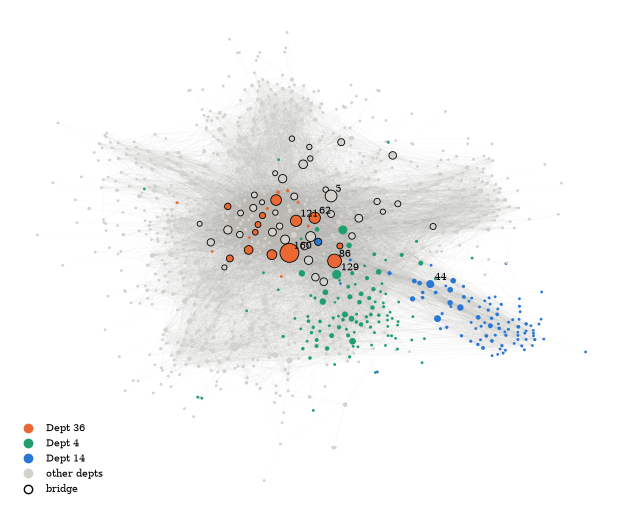

In [12]:
HIGHLIGHT = {36: ORANGE, 4: GREEN, 14: BLUE}
lcc_nodes = max(nx.connected_components(U), key=len)
L = U.subgraph(lcc_nodes)
pos = nx.forceatlas2_layout(L, max_iter=300, scaling_ratio=2.0, gravity=1.0, seed=SEED)

fig, ax = plt.subplots(figsize=(6.3, 5.2))
segs = [(pos[u], pos[v]) for u, v in L.edges()]
ax.add_collection(LineCollection(segs, colors="#b9b8b3", linewidths=0.2, alpha=0.12, zorder=0))
order = sorted(L.nodes(), key=lambda v: cent.at[v, "betweenness"])     # big nodes on top
xy = np.array([pos[v] for v in order])
sizes = 4 + 2500 * cent.loc[order, "betweenness"].values
colors = [HIGHLIGHT.get(dept[v], "#d3d2cd") for v in order]
edge = ["black" if cent.at[v, "role"] == "bridge" else "none" for v in order]
ax.scatter(xy[:, 0], xy[:, 1], s=sizes, c=colors, edgecolors=edge, linewidths=0.6, zorder=2)
for v in list(cent["betweenness"].nlargest(5).index) + [44, 129]:
    ax.annotate(str(v), pos[v], fontsize=7, xytext=(3, 3), textcoords="offset points", zorder=3)
handles = [Line2D([], [], marker="o", ls="", color=c, label=f"Dept {d}") for d, c in HIGHLIGHT.items()]
handles += [Line2D([], [], marker="o", ls="", color="#d3d2cd", label="other depts"),
            Line2D([], [], marker="o", ls="", mfc="white", mec="black", label="bridge")]
ax.legend(handles=handles, loc="lower left", frameon=False, fontsize=7)
ax.set_axis_off()
fig.tight_layout()
fig.savefig(OUT / "fig_5_2_network.png", dpi=250)
plt.show()

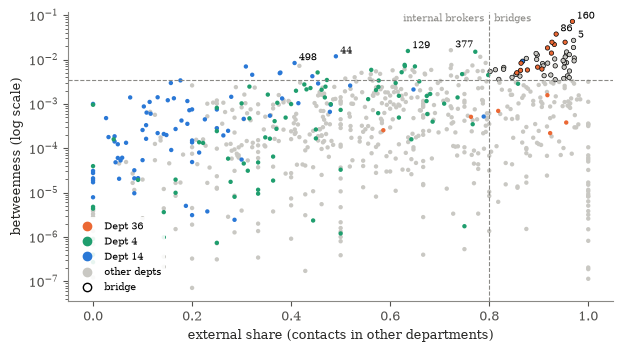

216 members with betweenness 0 are not shown (log scale)


In [13]:
fig, ax = plt.subplots(figsize=(6.3, 3.6))
pts = cent[(cent["contacts"] > 0) & (cent["betweenness"] > 0)]   # log scale cannot show 0
for d, c, lab, z in [(None, "#c9c8c3", "other depts", 1), (14, BLUE, "Dept 14", 2),
                     (4, GREEN, "Dept 4", 2), (36, ORANGE, "Dept 36", 3)]:
    sel = pts[~pts["dept"].isin(HIGHLIGHT)] if d is None else pts[pts["dept"] == d]
    ax.scatter(sel["external share"], sel["betweenness"], s=10, c=c, label=lab, zorder=z,
               edgecolors=["black" if r == "bridge" else "none" for r in sel["role"]], linewidths=0.5)
ax.axhline(b_thr, ls="--", lw=0.8, c=GREY)
ax.axvline(e_thr, ls="--", lw=0.8, c=GREY)
ax.set_yscale("log")
ax.set_xlabel("external share (contacts in other departments)")
ax.set_ylabel("betweenness (log scale)")
for v in [160, 86, 5, 129, 377, 44, 498]:
    ax.annotate(str(v), (cent.at[v, "external share"], cent.at[v, "betweenness"]),
                fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.text(e_thr + 0.01, 0.11, "bridges", ha="left", va="top", fontsize=7, color=GREY)
ax.text(e_thr - 0.01, 0.11, "internal brokers", ha="right", va="top", fontsize=7, color=GREY)
ax.set_ylim(top=0.12)
handles = [Line2D([], [], marker="o", ls="", color=c, label=lab)
           for c, lab in [(ORANGE, "Dept 36"), (GREEN, "Dept 4"), (BLUE, "Dept 14"), ("#c9c8c3", "other depts")]]
handles.append(Line2D([], [], marker="o", ls="", mfc="white", mec="black", label="bridge"))
ax.legend(handles=handles, fontsize=7, loc="lower left", facecolor="white", edgecolor="none", framealpha=0.9)
fig.tight_layout()
fig.savefig(OUT / "fig_5_2_bridges.png", dpi=250)
plt.show()
print(f"{len(active) - len(pts)} members with betweenness 0 are not shown (log scale)")
summary["fig_bridges_hidden_zero_betweenness"] = int(len(active) - len(pts))

## Step 11: Save the Gephi file and the summary

- `results/rq2_network.gexf`: open in Gephi (File → Open). Node attributes: `dept`, all centralities, `role`.
- `results/rq2_summary.json`: every number quoted in Section 5.2.

In [14]:
GX = G.copy()
for v in GX:
    for col in ["in-degree", "out-degree", "PageRank", "hub", "authority", "betweenness",
                "core number", "external share", "role"]:
        val = cent.at[v, col]
        GX.nodes[v][col.replace(" ", "_").replace("-", "_")] = (val if isinstance(val, str)
                                                                else float(np.nan_to_num(val)))
nx.write_gexf(GX, OUT / "rq2_network.gexf")


def to_jsonable(x):
    if isinstance(x, dict):
        return {str(k): to_jsonable(v) for k, v in x.items()}
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return None if np.isnan(x) else round(float(x), 6)
    return x


with open(OUT / "rq2_summary.json", "w") as f:
    json.dump(to_jsonable(summary), f, indent=1)
print("saved results/rq2_network.gexf and results/rq2_summary.json")
print("networkx", nx.__version__)

saved results/rq2_network.gexf and results/rq2_summary.json
networkx 3.7


## Measures considered but dropped

- **Closeness centrality**: in a directed network many pairs cannot reach each other (only 80% of members are in the largest strongly connected component), so closeness is either undefined or depends on how unreachable pairs are treated.
- **Eigenvector centrality**: on a directed network that is not strongly connected it gives zero to many members; PageRank solves this with the damping factor, so we use PageRank.
- **Gould-Fernandez brokerage roles**: would classify *how* members broker between departments, but needs a role table for 42 departments, too long for our word budget.